# Onde estão as empresas e os empregos no Polo Petrolina–Juazeiro

**Problema de negócio:** uma assessoria empresarial do Vale do São Francisco quer decidir onde prospectar. Quais setores concentram mais estabelecimentos e empregos na região, em quais a região é mais especializada que o Brasil e o que cresceu entre 2022 e 2024?

**Dados:** Cadastro Central de Empresas do IBGE (SIDRA, tabelas 9509 e 9510), baixados por `baixar.py`.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)
db = duckdb.connect()
db.execute("create table totais as select * from read_csv_auto('dados/totais_9509.csv')")
db.execute("create table setores as select * from read_csv_auto('dados/setores_9510.csv')")
COR, CINZA = "#2563eb", "#9ca3af"
def salvar(fig, nome):
    fig.tight_layout(); fig.savefig(f"imagens/{nome}.png", dpi=150); plt.show()

## 1. Quanto os três maiores municípios representam da região

O IBGE só abre os dados por setor para municípios com 50 mil habitantes ou mais. Na RIDE, são Petrolina, Juazeiro e Casa Nova. Antes de seguir, vale medir quanto eles representam.

In [2]:
peso = db.sql('''
    select ano,
           sum(valor) filter (where codigo_local in (2611101, 2918407, 2907202)) as tres_maiores,
           sum(valor) filter (where codigo_local <> 1) as ride
    from totais where variavel = 'pessoal_ocupado' group by ano order by ano
''').df()
peso["participacao_%"] = 100 * peso.tres_maiores / peso.ride
peso

,ano,tres_maiores,ride,participacao_%
0,2022,"150,877.00","165,935.00",90.93
1,2023,"153,771.00","169,231.00",90.86
2,2024,"167,090.00","183,643.00",90.99


## 2. Os setores que mais empregam (Petrolina + Juazeiro + Casa Nova, 2024)

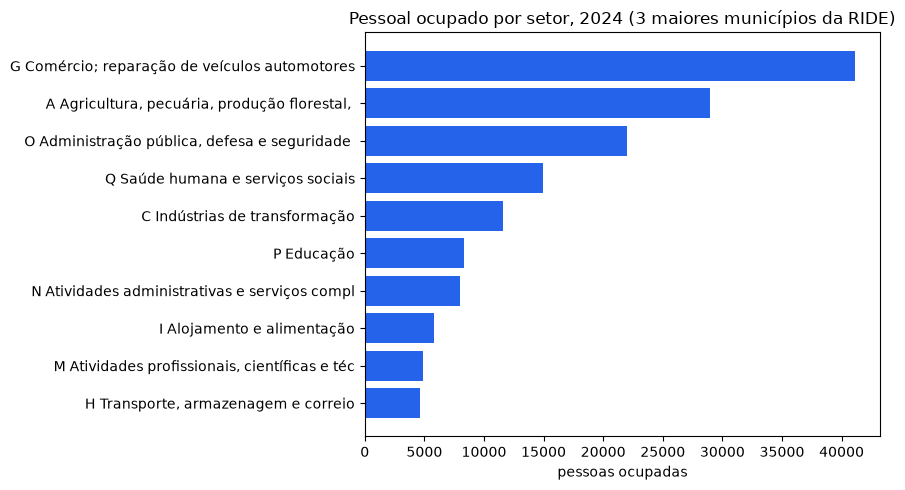

,setor,pessoal,unidades
0,G Comércio; reparação de veículos automotores ...,"41,165.00","9,779.00"
1,"A Agricultura, pecuária, produção florestal, p...","28,945.00",724.00
2,"O Administração pública, defesa e seguridade s...","22,012.00",87.00
3,Q Saúde humana e serviços sociais,"14,984.00","2,079.00"
4,C Indústrias de transformação,"11,611.00","1,155.00"
5,P Educação,"8,333.00","1,148.00"
6,N Atividades administrativas e serviços comple...,"8,014.00","1,596.00"
7,I Alojamento e alimentação,"5,819.00","1,178.00"
8,"M Atividades profissionais, científicas e técn...","4,913.00","1,671.00"
9,"H Transporte, armazenagem e correio","4,647.00",912.00


In [3]:
regiao = db.sql('''
    select setor,
           sum(valor) filter (where variavel = 'pessoal_ocupado') as pessoal,
           sum(valor) filter (where variavel = 'unidades_locais') as unidades
    from setores
    where ano = 2024 and codigo_local <> 1 and setor <> 'Total'
    group by setor order by pessoal desc
''').df()
regiao["setor_curto"] = regiao.setor.str.slice(0, 45)
top = regiao.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.setor_curto, top.pessoal, color=COR)
ax.set_title("Pessoal ocupado por setor, 2024 (3 maiores municípios da RIDE)")
ax.set_xlabel("pessoas ocupadas")
salvar(fig, "1-setores-que-mais-empregam")
regiao.head(10)[["setor", "pessoal", "unidades"]]

## 3. Em que a região é especializada (quociente locacional)

QL = (participação do setor no emprego da região) ÷ (participação do setor no emprego do Brasil). QL acima de 1 indica que a região emprega proporcionalmente mais naquele setor do que o país.

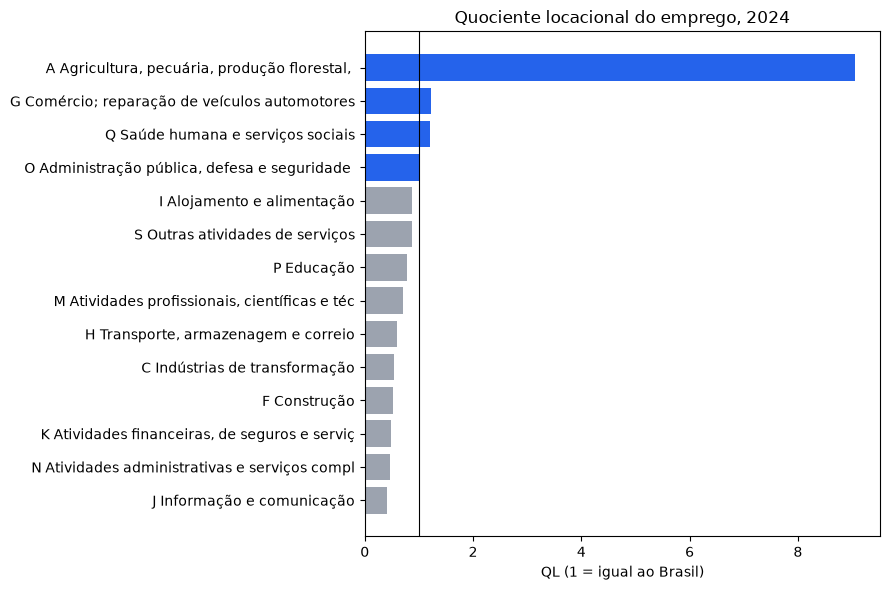

,setor,fatia_regiao_pct,fatia_brasil_pct,ql
0,"A Agricultura, pecuária, produção florestal, p...",17.32,1.91,9.06
1,D Eletricidade e gás,0.36,0.25,1.43
2,"E Água, esgoto, atividades de gestão de resídu...",0.96,0.74,1.30
3,G Comércio; reparação de veículos automotores ...,24.64,20.11,1.22
4,Q Saúde humana e serviços sociais,8.97,7.39,1.21
5,B Indústrias extrativas,0.46,0.43,1.07
6,"R Artes, cultura, esporte e recreação",0.88,0.84,1.05
7,"O Administração pública, defesa e seguridade s...",13.17,12.85,1.02
8,I Alojamento e alimentação,3.48,3.95,0.88
9,S Outras atividades de serviços,1.99,2.29,0.87


In [4]:
ql = db.sql('''
    with base as (
        select case when codigo_local = 1 then 'brasil' else 'regiao' end as onde, setor, sum(valor) as pessoal
        from setores where ano = 2024 and variavel = 'pessoal_ocupado'
        group by all
    ), part as (
        select b.onde, b.setor, b.pessoal / t.pessoal as fatia
        from base b join base t on t.onde = b.onde and t.setor = 'Total'
        where b.setor <> 'Total'
    )
    select r.setor, r.fatia * 100 as fatia_regiao_pct, b.fatia * 100 as fatia_brasil_pct, r.fatia / b.fatia as ql
    from part r join part b on b.setor = r.setor and b.onde = 'brasil'
    where r.onde = 'regiao' and b.fatia > 0
    order by ql desc
''').df()
ql["setor_curto"] = ql.setor.str.slice(0, 45)
q = ql[ql.fatia_regiao_pct >= 1].sort_values("ql")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(q.setor_curto, q.ql, color=[COR if v >= 1 else CINZA for v in q.ql])
ax.axvline(1, color="black", linewidth=0.8)
ax.set_title("Quociente locacional do emprego, 2024")
ax.set_xlabel("QL (1 = igual ao Brasil)")
salvar(fig, "2-quociente-locacional")
ql[["setor", "fatia_regiao_pct", "fatia_brasil_pct", "ql"]]

## 4. O que cresceu entre 2022 e 2024

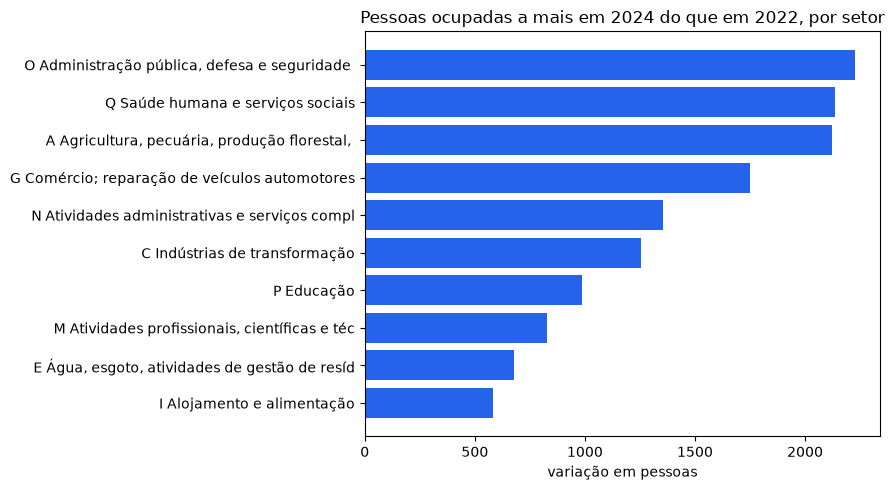

,setor,pessoal_2022,pessoal_2024,variacao_pessoal_%,unidades_2022,unidades_2024,variacao_unidades_%
1,Total,"150,877.00","167,090.00",10.75,"22,013.00","25,457.00",15.65
18,"O Administração pública, defesa e seguridade s...","19,783.00","22,012.00",11.27,79.00,87.00,10.13
16,Q Saúde humana e serviços sociais,"12,850.00","14,984.00",16.61,"1,538.00","2,079.00",35.18
14,"A Agricultura, pecuária, produção florestal, p...","26,823.00","28,945.00",7.91,613.00,724.00,18.11
13,G Comércio; reparação de veículos automotores ...,"39,415.00","41,165.00",4.44,"8,917.00","9,779.00",9.67
15,N Atividades administrativas e serviços comple...,"6,659.00","8,014.00",20.35,"1,357.00","1,596.00",17.61
12,C Indústrias de transformação,"10,354.00","11,611.00",12.14,"1,018.00","1,155.00",13.46
19,P Educação,"7,345.00","8,333.00",13.45,"1,035.00","1,148.00",10.92
0,"M Atividades profissionais, científicas e técn...","4,086.00","4,913.00",20.24,"1,307.00","1,671.00",27.85
7,"E Água, esgoto, atividades de gestão de resídu...",925.00,"1,603.00",73.30,80.00,87.00,8.75


In [5]:
cres = db.sql('''
    select setor,
           sum(valor) filter (where ano = 2022 and variavel = 'pessoal_ocupado') as pessoal_2022,
           sum(valor) filter (where ano = 2024 and variavel = 'pessoal_ocupado') as pessoal_2024,
           sum(valor) filter (where ano = 2022 and variavel = 'unidades_locais') as unidades_2022,
           sum(valor) filter (where ano = 2024 and variavel = 'unidades_locais') as unidades_2024
    from setores where codigo_local <> 1 group by setor
''').df()
cres["variacao_pessoal"] = cres.pessoal_2024 - cres.pessoal_2022
cres["variacao_pessoal_%"] = 100 * cres.variacao_pessoal / cres.pessoal_2022
cres["variacao_unidades_%"] = 100 * (cres.unidades_2024 - cres.unidades_2022) / cres.unidades_2022
cres["setor_curto"] = cres.setor.str.slice(0, 45)
g = cres[cres.setor != "Total"].sort_values("variacao_pessoal").tail(10)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(g.setor_curto, g.variacao_pessoal, color=COR)
ax.set_title("Pessoas ocupadas a mais em 2024 do que em 2022, por setor")
ax.set_xlabel("variação em pessoas")
salvar(fig, "3-crescimento-2022-2024")
cres.sort_values("variacao_pessoal", ascending=False)[["setor", "pessoal_2022", "pessoal_2024", "variacao_pessoal_%", "unidades_2022", "unidades_2024", "variacao_unidades_%"]]

## 5. Petrolina e Juazeiro lado a lado

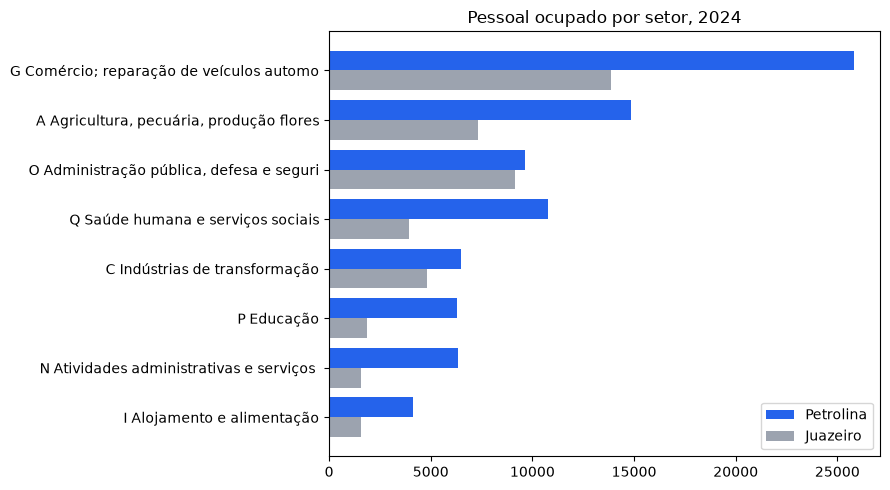

,setor,petrolina,juazeiro
0,G Comércio; reparação de veículos automotores ...,"25,807.00","13,844.00"
1,"A Agricultura, pecuária, produção florestal, p...","14,848.00","7,347.00"
2,"O Administração pública, defesa e seguridade s...","9,660.00","9,161.00"
3,Q Saúde humana e serviços sociais,"10,775.00","3,946.00"
4,C Indústrias de transformação,"6,494.00","4,824.00"
5,P Educação,"6,298.00","1,867.00"
6,N Atividades administrativas e serviços comple...,"6,351.00","1,546.00"
7,I Alojamento e alimentação,"4,149.00","1,575.00"


In [6]:
lado = db.sql('''
    select setor,
           sum(valor) filter (where codigo_local = 2611101) as petrolina,
           sum(valor) filter (where codigo_local = 2918407) as juazeiro
    from setores where ano = 2024 and variavel = 'pessoal_ocupado' and setor <> 'Total'
    group by setor order by petrolina + juazeiro desc limit 8
''').df()
lado["setor_curto"] = lado.setor.str.slice(0, 40)
l = lado.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
y = range(len(l))
ax.barh([i + 0.2 for i in y], l.petrolina, height=0.4, color=COR, label="Petrolina")
ax.barh([i - 0.2 for i in y], l.juazeiro, height=0.4, color=CINZA, label="Juazeiro")
ax.set_yticks(list(y), l.setor_curto)
ax.legend(); ax.set_title("Pessoal ocupado por setor, 2024")
salvar(fig, "4-petrolina-e-juazeiro")
lado[["setor", "petrolina", "juazeiro"]]

## 6. Onde prospectar

Para uma assessoria, o número de **unidades locais** é o tamanho da lista de possíveis clientes, e o **crescimento** indica onde há empresas abrindo ou contratando. A tabela junta as duas coisas.

In [7]:
alvo = cres[cres.setor != "Total"].merge(ql[["setor", "ql"]], on="setor", how="left")
alvo = alvo[alvo.unidades_2024 >= 100].sort_values(["unidades_2024"], ascending=False)
alvo[["setor", "unidades_2024", "variacao_unidades_%", "pessoal_2024", "variacao_pessoal_%", "ql"]].head(10)

,setor,unidades_2024,variacao_unidades_%,pessoal_2024,variacao_pessoal_%,ql
12,G Comércio; reparação de veículos automotores ...,"9,779.00",9.67,"41,165.00",4.44,1.22
15,Q Saúde humana e serviços sociais,"2,079.00",35.18,"14,984.00",16.61,1.21
16,S Outras atividades de serviços,"1,816.00",10.40,"3,317.00",16.47,0.87
0,"M Atividades profissionais, científicas e técn...","1,671.00",27.85,"4,913.00",20.24,0.71
14,N Atividades administrativas e serviços comple...,"1,596.00",17.61,"8,014.00",20.35,0.47
7,F Construção,"1,382.00",19.14,"4,110.00",3.60,0.53
3,I Alojamento e alimentação,"1,178.00",18.51,"5,819.00",11.09,0.88
11,C Indústrias de transformação,"1,155.00",13.46,"11,611.00",12.14,0.54
18,P Educação,"1,148.00",10.92,"8,333.00",13.45,0.78
19,"H Transporte, armazenagem e correio",912.00,14.72,"4,647.00",9.94,0.59


## Limitações

- O IBGE só publica a abertura por setor para municípios com 50 mil habitantes ou mais. Os outros 5 municípios da RIDE entram apenas nos totais (seção 1).
- Os dados vêm do cadastro de CNPJs (inclui órgãos públicos e entidades sem fins lucrativos) e não incluem trabalho informal, que é relevante na agricultura irrigada da região.
- "Unidades locais" contam estabelecimentos, não empresas: uma rede com três lojas vale três.
- A série 9509/9510 começa em 2022; para períodos anteriores, a metodologia muda (tabelas 6449 e 6450).